# Исследовательский анализ данных

In [1]:
import pandas as pd
from pathlib import Path
from PIL import Image
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


## Манифест

In [2]:
dataset_path = Path("../data/raw/lighting/train")

records = []

for class_dir in dataset_path.iterdir():
    for image_path in class_dir.glob("*.png"):
        with Image.open(image_path) as image:
            records.append({
                    "path": str(image_path),
                    "label": class_dir.name,
                    "width": image.width,
                    "height": image.height,
                    "mode": image.mode,
                    "file_size": image_path.stat().st_size
                }
                          )
df = pd.DataFrame(records)

excepted_labels = df["label"].unique()

ordered = pd.CategoricalDtype(categories=["dark", "normal", "bright"], ordered=True)
df["label"] = df["label"].astype(ordered)
for col in ("width", "height", "file_size"):
    df[col] = pd.to_numeric(df[col], downcast="unsigned")


После преобразований типов

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   path       1500 non-null   str     
 1   label      1500 non-null   category
 2   width      1500 non-null   uint16  
 3   height     1500 non-null   uint16  
 4   mode       1500 non-null   str     
 5   file_size  1500 non-null   uint32  
dtypes: category(1), str(2), uint16(2), uint32(1)
memory usage: 36.9 KB


In [4]:
df.head()

,path,label,width,height,mode,file_size
0,../data/raw/lighting/train/normal/a3cd2458-bbe...,normal,512,512,RGB,509595
1,../data/raw/lighting/train/normal/2aeae592-9b6...,normal,512,512,RGB,499344
2,../data/raw/lighting/train/normal/3d2a84fc-5b2...,normal,512,512,RGB,509520
3,../data/raw/lighting/train/normal/50a1d152-221...,normal,512,512,RGB,505425
4,../data/raw/lighting/train/normal/ca033a0c-114...,normal,512,512,RGB,499141


## Распределение метаданных по классам
Все изображения имеют одинаковый размер 512 x 512 пикселей

In [5]:
df.groupby("label", observed=True)[
    ["width", "height"]
    ].describe()

width                                                height         \
        count   mean  std    min    25%    50%    75%    max  count   mean   
label                                                                        
dark    500.0  512.0  0.0  512.0  512.0  512.0  512.0  512.0  500.0  512.0   
normal  500.0  512.0  0.0  512.0  512.0  512.0  512.0  512.0  500.0  512.0   
bright  500.0  512.0  0.0  512.0  512.0  512.0  512.0  512.0  500.0  512.0   

                                                
        std    min    25%    50%    75%    max  
label                                           
dark    0.0  512.0  512.0  512.0  512.0  512.0  
normal  0.0  512.0  512.0  512.0  512.0  512.0  
bright  0.0  512.0  512.0  512.0  512.0  512.0

In [6]:
df.groupby("label", observed=True)[
    ["file_size"]
    ].describe()

file_size                                                         \
           count        mean          std       min       25%       50%   
label                                                                     
dark       500.0  500798.716  6116.822997  489739.0  496312.0  499207.0   
normal     500.0  503377.588  7162.177853  492300.0  498113.5  501499.0   
bright     500.0  502915.256  6447.619258  491714.0  497877.5  501641.5   

                             
              75%       max  
label                        
dark    504169.25  522336.0  
normal  508289.50  530528.0  
bright  506935.75  536537.0

In [7]:
df["mode"].value_counts()

mode
RGB    1500
Name: count, dtype: int64

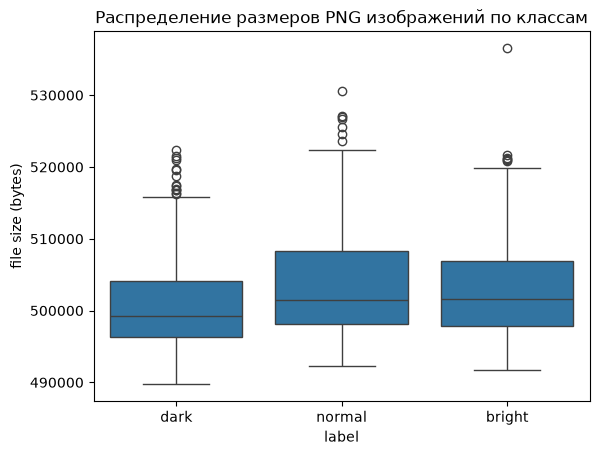

In [8]:

sns.boxplot(data=df, x="label", y="file_size")

plt.title("Распределение размеров PNG изображений по классам")
plt.xlabel("label")
plt.ylabel("file size (bytes)")
plt.show()

## Исследование освещенности по изображениям

In [9]:
def srgb_to_linear(rgb: np.ndarray) -> np.ndarray:
    rgb = rgb / 255.0

    return np.where(
        rgb <= 0.04045,
        rgb / 12.92,
        ((rgb + 0.055) / 1.055) ** 2.4,
    )


def calculate_luminance(rgb: np.ndarray) -> np.ndarray:
    linear_rgb = srgb_to_linear(rgb)

    return (
        0.2126 * linear_rgb[..., 0]
        + 0.7152 * linear_rgb[..., 1]
        + 0.0722 * linear_rgb[..., 2]
    )

In [10]:
def extract_rgb_stats(image_path: str):
    with Image.open(image_path) as image:
        pixels = np.asarray(image, dtype=np.float32)
        luminance = calculate_luminance(pixels)
    return {
        "mean_R": pixels[:, :, 0].mean(),
        "mean_G": pixels[:, :, 1].mean(),
        "mean_B": pixels[:, :, 2].mean(),
        "std_R": pixels[:, :, 0].std(),
        "std_G": pixels[:, :, 1].std(),
        "std_B": pixels[:, :, 2].std(),
        "mean_luminance": luminance.mean(),
        "std_luminance": luminance.std()
    }
    


In [11]:
rgb_stats = df["path"].map(extract_rgb_stats)

stats_df = rgb_stats.apply(pd.Series)

df = df.join(stats_df)

In [12]:
df.groupby("label", observed=True)[
    ["mean_R", "std_R"]].describe()

mean_R                                                         \
        count       mean        std        min        25%        50%   
label                                                                  
dark    500.0  64.391571  19.299168  15.387943  51.042216  62.778481   
normal  500.0  82.622681  19.388208  35.706245  68.660133  82.419949   
bright  500.0  81.326096  19.605677  42.405281  67.316954  79.941978   

                               std_R                                   \
              75%         max  count       mean        std        min   
label                                                                   
dark    76.615616  124.811859  500.0  40.219376  10.545777   8.619488   
normal  95.923901  153.690125  500.0  41.618473  10.088833  15.190141   
bright  93.144619  170.140625  500.0  42.878632  10.013315  18.264009   

                                                    
              25%        50%        75%        max  
label                                               
dark    33.012196  40.064693  46.903754  75.161263  
normal  34.857321  40.576290  48.574134  78.510536  
bright  36.233393  42.281626  48.920727  86.223839

In [13]:
df.groupby("label", observed=True)[
    ["mean_G", "std_G"]].describe()

mean_G                                                         \
        count       mean        std        min        25%        50%   
label                                                                  
dark    500.0  65.915726  18.442749  16.305725  53.428809  64.570396   
normal  500.0  83.577156  18.942610  36.538506  71.051905  83.288158   
bright  500.0  82.199257  19.277849  38.709839  68.352127  81.509453   

                               std_G                                   \
              75%         max  count       mean        std        min   
label                                                                   
dark    77.729408  121.539680  500.0  40.641300  10.404462   8.551003   
normal  96.142563  150.405731  500.0  42.283585   9.592282  15.385023   
bright  93.439205  161.835999  500.0  43.213188   9.654286  19.623510   

                                                    
              25%        50%        75%        max  
label                                               
dark    33.555844  40.482462  46.676843  75.355774  
normal  36.024541  42.039627  49.181682  74.918137  
bright  36.608861  42.560650  49.522688  75.147995

In [14]:
df.groupby("label", observed=True)[
    ["mean_B", "std_B"]].describe()

mean_B                                                         \
        count       mean        std        min        25%        50%   
label                                                                  
dark    500.0  53.375916  17.619019  12.978325  40.474278  52.587332   
normal  500.0  68.463753  18.331850  27.275219  55.149237  68.328720   
bright  500.0  67.632866  18.453209  24.172916  53.844650  66.531567   

                               std_B                                   \
              75%         max  count       mean        std        min   
label                                                                   
dark    64.272564  110.469147  500.0  36.639748  10.249921   6.505136   
normal  81.809750  139.811401  500.0  39.797791   9.641069  11.717819   
bright  78.390530  136.474487  500.0  39.796616   9.404507  15.689824   

                                                    
              25%        50%        75%        max  
label                                               
dark    29.830543  36.825087  42.732527  74.859398  
normal  33.638694  39.735374  45.817166  68.983109  
bright  33.260715  39.321192  44.945662  69.042671

In [15]:
df.groupby("label", observed=True)[
    ["mean_luminance", "std_luminance"]].describe()

mean_luminance                                                    \
                count      mean       std       min       25%       50%   
label                                                                     
dark            500.0  0.083331  0.042141  0.005793  0.053575  0.076784   
normal          500.0  0.119741  0.050090  0.024529  0.084886  0.114663   
bright          500.0  0.118285  0.052273  0.029000  0.080556  0.110220   

                           std_luminance                                \
             75%       max         count      mean       std       min   
label                                                                    
dark    0.103491  0.249724         500.0  0.092934  0.039839  0.004123   
normal  0.151043  0.383064         500.0  0.106040  0.041204  0.014508   
bright  0.143934  0.406680         500.0  0.107675  0.041015  0.028129   

                                                
             25%       50%       75%       max  
label                                           
dark    0.064741  0.089400  0.115224  0.233561  
normal  0.078605  0.100609  0.130598  0.259089  
bright  0.078458  0.101428  0.132492  0.256433

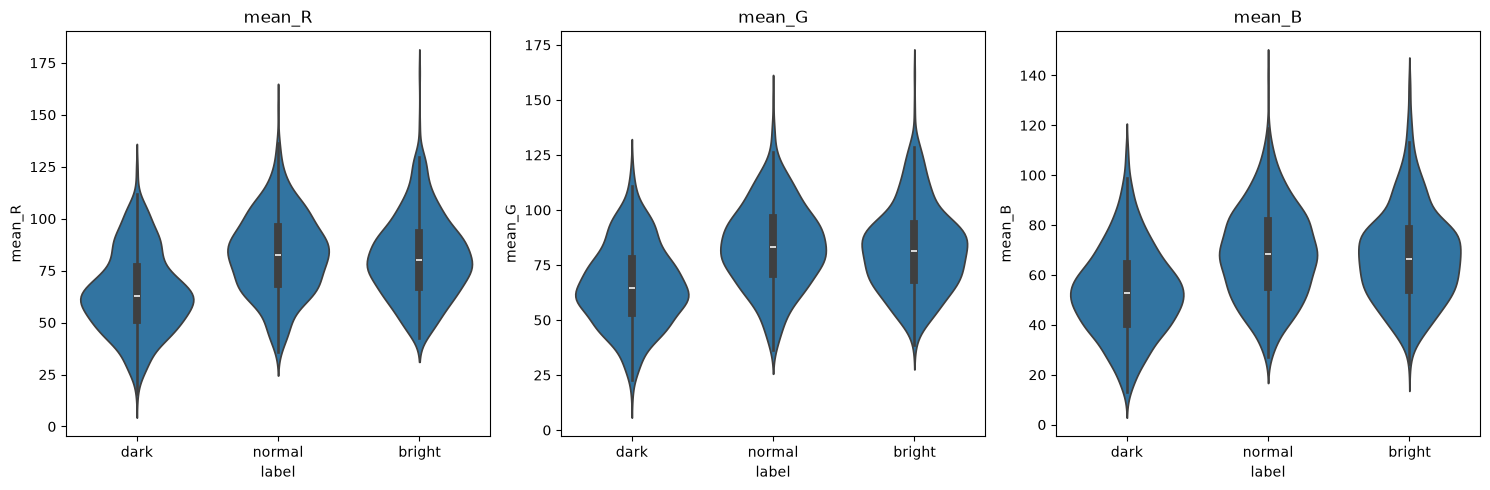

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, ["mean_R", "mean_G", "mean_B"]):
    sns.violinplot(
        data=df,
        x="label",
        y=col,
        order=["dark", "normal", "bright"],
        ax=ax,
    )
    ax.set_title(col)

plt.tight_layout()
plt.show()

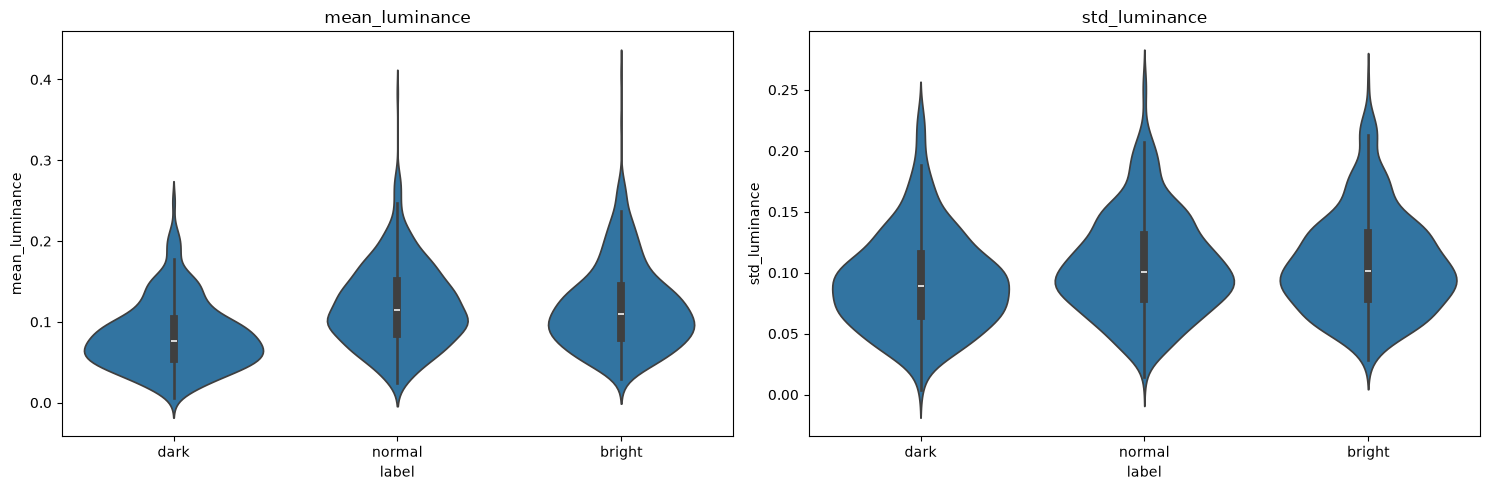

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, col in zip(axes, ["mean_luminance", "std_luminance"]):
    sns.violinplot(
        data=df,
        x="label",
        y=col,
        order=["dark", "normal", "bright"],
        ax=ax,
    )
    ax.set_title(col)

plt.tight_layout()
plt.show()